# MLP_JK_02 — PCA input, shrinkage toward the mean, and a small settings grid

**Why this notebook**

In MLP_JK_01, the MLP on `center+mean-3x3` had the highest test pooled PCC so far (0.216), but both MLPs had a **higher NRMSE than the mean predictor**. Their predictions were partly in the right order, but too spread out or at the wrong level. The loss curves showed the network memorizing the training patients within a few epochs. This notebook tries three ways to fix that:

1. **PCA input.** StandardScaler + PCA 256, fit on the training patients (the same as ridge). 256 numbers instead of 4,608 or 9,216 means far fewer weights to overfit with.
2. **Shrinkage toward the training mean.** Final prediction = `train_mean + k × (MLP prediction − train_mean)`, with `k` from [0.2, 0.4, 0.6, 0.8, 1.0]. `k = 1` is the plain MLP; smaller `k` pulls every prediction toward the average, which is what ridge's large λ does.
3. **A small grid** of hidden size [64, 128] × dropout [0.3, 0.5] × weight decay [1e-4, 1e-3] = 8 settings.

**How settings are chosen (training patients only, separately in each fold)**
- The training patients are split into 4 groups by patient. Each group takes a turn as the validation set, and the scores are averaged over all 4 turns (in 01 only one group was used, which was noisy).
- For each setting, `k` = the value with the lowest validation NRMSE.
- Keep settings whose validation NRMSE is no worse than the mean predictor's; of those, pick the highest validation PCC.
- The chosen setting is retrained on **all** training patients with 3 seeds, and the 3 predictions are averaged.

The test patients are used once, at the end, to score the final model. Test scores are reported but never used to choose.

| Condition | Input |
|---|---|
| `mean predictor` | — |
| `ridge raw` | copied from Notebook 5 (re-run, must reproduce 0.187) |
| `ridge center+mean-3x3 (Notebook 5)` | best ridge, read from Notebook 5's saved scores |
| `MLP raw` | PCA 256 of each spot's own embedding |
| `MLP center+mean-3x3` | PCA 256 of the spot's embedding next to its 3×3 average |

**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_02/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores, used to check the ridge rerun and for the best-ridge reference row.
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5, so the numbers are comparable)
- `N_FOLDS = 4` patient folds, `N_GENES = 50` top-variance genes, `MIN_TEST_SD = 0.05` (genes that barely vary in a test set are left out of NRMSE), `SEED = 0`.
- `N_PCS = 256`, `N_INNER_FOLDS`, `ALPHAS`: the ridge settings. `N_PCS` is also the size of the MLP's input now.
- `NEIGHBOR_DISTANCE = 1.8` spot spacings = the 3×3 square.

**MLP**
- `HIDDEN_SIZES`, `DROPOUTS`, `WEIGHT_DECAYS`: the grid. Every combination is tried (2 × 2 × 2 = 8 settings).
- `SHRINK_FACTORS`: the values of `k` to try.
- `N_VAL_GROUPS = 4`: the training patients are split into 4 groups by patient, and each group takes a turn as the validation set.
- `LEARNING_RATE`, `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`: as in 01.
- `N_FINAL_SEEDS = 3`: the chosen setting is retrained 3 times with different random starts, and the predictions are averaged. Averaging smooths out the luck of any single run.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
NOTEBOOK_5_DIR = os.path.expanduser("~/JHU/BDD/Experiments/smoothing_control")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
NOTEBOOK_NAME = "MLP_JK_02"
LOG_RESULTS = True
MLP_CONDITIONS = ["raw", "center+mean-3x3"]
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
N_PCS = 256
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0
NEIGHBOR_DISTANCE = 1.8

HIDDEN_SIZES = [64, 128]
DROPOUTS = [0.3, 0.5]
WEIGHT_DECAYS = [1e-4, 1e-3]
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
N_FINAL_SEEDS = 3

The grid as a list of settings, numbered 0–7. The device is the Apple GPU (`mps`) if it's available, otherwise the CPU. Seeds are fixed for numpy and torch. (The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.)

In [3]:
GRID = []
for hidden in HIDDEN_SIZES:
    for dropout in DROPOUTS:
        for weight_decay in WEIGHT_DECAYS:
            GRID.append({"hidden": hidden, "dropout": dropout, "weight_decay": weight_decay})
print(pd.DataFrame(GRID).rename_axis("setting").to_string())

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("\nDevice:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

         hidden  dropout  weight_decay
setting                               
0            64      0.3        0.0001
1            64      0.3        0.0010
2            64      0.5        0.0001
3            64      0.5        0.0010
4           128      0.3        0.0001
5           128      0.3        0.0010
6           128      0.5        0.0001
7           128      0.5        0.0010

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Neighborhoods and the center+mean-3x3 input (copied from Notebook 5)

For each section:
1. **Spot spacing** = median distance from a spot to its closest other spot.
2. A spot's **neighborhood** = every spot on the same section within 1.8 × spacing, **including the spot itself**. That is the 3×3 square.
3. The averaged embedding = the plain mean over the neighborhood. Spots at the tissue edge have fewer than 9 and are averaged over what exists.

`center+mean-3x3` puts the spot's own embedding next to its neighborhood average: 4,608 + 4,608 = 9,216 numbers. The averages use images only, from the same section.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


neighborhoods_3x3 = find_neighborhoods(NEIGHBOR_DISTANCE)
sizes = np.array([len(n) for n in neighborhoods_3x3])
print(f"3x3: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, "
      f"min {sizes.min()}, max {sizes.max()} | full (9): {np.mean(sizes == 9):.1%}")


def make_embeddings(condition):
    if condition == "raw":
        return X_raw
    if condition == "center+mean-3x3":
        return np.concatenate([X_raw, neighbor_mean(X_raw, neighborhoods_3x3)], axis=1)
    raise ValueError(f"unknown condition {condition}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10 | full (9): 70.7%


## Step 3. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. Each fold is the test set once.

In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 4. Gene choice and scoring (copied from Notebook 5)

**`choose_genes`**: the 50 genes with the highest variance across the **training** spots of a fold.

**`score_model`** gives two kinds of score for every gene:
- **Pooled**: over all test spots of the fold together. **PCC** = correlation between predicted and true expression. **NRMSE** = prediction error divided by the gene's spread (SD) in the test spots.
- **Within patient**: the same, but inside one test patient at a time, then averaged. This asks whether the model ranks spots correctly *within* a tissue, not just whether it gets the patient's overall level right.

The **mean predictor** predicts the training mean for every spot. Its PCC is undefined (the prediction is constant), and its NRMSE is the bar any useful model should get under.

In [7]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)

## Step 5. Ridge on raw embeddings (copied from Notebook 5), and the reproduction check

Inside each fold, using **training spots only**: choose the top-50 genes, fit StandardScaler + PCA 256, choose λ per gene with a 3-group patient split of the training patients, fit ridge, predict the test patients. The mean predictor comes from the same fold (the training mean of each gene).

Then the **check**: the pooled PCC and NRMSE must match Notebook 5's `ridge raw` (0.187 / 1.092). If they don't, the `assert` stops the notebook here, because then the setup isn't the same and nothing below would be comparable.

In [8]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred


def run_ridge_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler(copy=False)
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    pca = PCA(n_components=N_PCS, random_state=SEED, copy=False)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, patient_array[train_index])
    y_pred = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    return {
        "fold": fold,
        "test_index": test_index,
        "genes": all_genes[gene_index],
        "y_test": y_test,
        "y_pred": y_pred,
        "y_mean": y_mean,
        "alpha": alpha_per_gene,
    }


start_time = time.time()
ridge_results = []
for fold in range(N_FOLDS):
    ridge_results.append(run_ridge_fold(X_raw, fold))
    print(f"ridge raw fold {fold} done  ({(time.time() - start_time) / 60:.1f} min)", flush=True)

ridge raw fold 0 done  (0.1 min)


ridge raw fold 1 done  (0.2 min)


ridge raw fold 2 done  (0.3 min)


ridge raw fold 3 done  (0.4 min)


In [9]:
mean_pooled, mean_within = score_model("mean predictor", ridge_results, "y_mean")
ridge_pooled, ridge_within = score_model("ridge raw", ridge_results, "y_pred")

notebook_5_summary = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "summary.csv")).set_index("model")
our_pcc = ridge_pooled["PCC"].mean()
our_nrmse = ridge_pooled["NRMSE"].mean()
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]

print(f"ridge raw, this notebook: pooled PCC {our_pcc:.4f}, NRMSE {our_nrmse:.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")

assert abs(our_pcc - notebook_5_pcc) < 0.001 and abs(our_nrmse - notebook_5_nrmse) < 0.001, \
    "Ridge rerun does not reproduce Notebook 5. Stop and find out why before going further."
print("Reproduces Notebook 5.")

ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0917
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917
Reproduces Notebook 5.


## Step 6. The MLP input: StandardScaler + PCA 256 (the same as ridge)

In each fold, the StandardScaler and PCA are fit on the fold's **training patients**, then used to transform every spot. This is the same transformation ridge uses, so the MLP and ridge see the same 256 numbers per spot.

The validation runs inside a fold use this same PCA. That is how ridge chose its λ too. The validation patients are training patients, and PCA only looks at images, never at expression, so nothing from the test patients leaks in.

In [10]:
def make_pca_input(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    P = pca.transform(scaler.transform(X))
    return P.astype(np.float32)

## Step 7. The MLP, training, and shrinkage

**The network**: input (256) → Linear(256, hidden) → ReLU → Dropout → Linear(hidden, 50 genes), with no activation at the end (regression).

**`train_mlp`**: as in 01, but the hidden size, dropout and weight decay come from the setting being tried, and the seed can be changed. Each of the 50 genes is standardized with the training mean and SD, so every gene counts about equally in the MSE loss. With validation spots, the weights from the best validation epoch are kept, and training stops after `PATIENCE` epochs without improvement. Without validation spots, it trains for a fixed number of epochs.

**`predict`**: dropout off, predictions converted back to log1p units.

**`shrink`**: `train_mean + k × (prediction − train_mean)`. A useful fact: shrinking doesn't change PCC at all. Multiplying every prediction's distance from the mean by the same `k` keeps the order and the shape of the predictions. It only changes how spread out they are, so it can only change NRMSE. That's why `k` is chosen on NRMSE.

In [11]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, setting, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], setting["hidden"], N_GENES, setting["dropout"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=setting["weight_decay"])
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 8. The validation grid inside one fold

The fold's training patients are split into 4 groups by patient (`validation_groups`). For each group in turn:
- the other 3 groups are the **fit** patients, and this group is the **validation** set
- every setting in the grid is trained on the fit patients, with early stopping on the validation patients
- the validation predictions are scored at every `k`, shrinking toward the fit patients' mean
- the mean predictor (the fit patients' mean) is scored on the same validation patients

The same `score_model` function as for the test scores is used, so "validation PCC" and "validation NRMSE" mean exactly the same thing as the test scores, just on different patients.

In [12]:
def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_grid(P_device, y_fold, train_index, genes, fold):
    no_alpha = np.full(N_GENES, np.nan)
    grid_rows = []
    histories = []

    for group, (fit_rows, val_rows) in enumerate(validation_groups(train_index)):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {
            "fold": fold,
            "test_index": val_rows,
            "genes": genes,
            "y_test": y_fold[val_rows],
            "y_mean": np.tile(fit_mean, (len(val_rows), 1)),
            "alpha": no_alpha,
        }
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")
        mean_nrmse = mean_scores["NRMSE"].mean()

        for setting_number, setting in enumerate(GRID):
            trained = train_mlp(P_device, y_fold, fit_rows, val_rows, MAX_EPOCHS, setting, SEED)
            val_pred = predict(trained, P_device, val_rows)

            for k in SHRINK_FACTORS:
                val_result["y_pred"] = shrink(val_pred, fit_mean, k)
                scores, _ = score_model("MLP", [val_result], "y_pred")
                grid_rows.append({
                    "fold": fold,
                    "val_group": group,
                    "setting": setting_number,
                    "hidden": setting["hidden"],
                    "dropout": setting["dropout"],
                    "weight_decay": setting["weight_decay"],
                    "k": k,
                    "val_PCC": scores["PCC"].mean(),
                    "val_NRMSE": scores["NRMSE"].mean(),
                    "val_mean_predictor_NRMSE": mean_nrmse,
                    "best_epoch": trained["best_epoch"],
                })

            history = pd.DataFrame(trained["history"])
            history["fold"] = fold
            history["val_group"] = group
            history["setting"] = setting_number
            history["best_epoch"] = trained["best_epoch"]
            histories.append(history)

    return pd.DataFrame(grid_rows), pd.concat(histories, ignore_index=True)

## Step 9. Choosing the setting and `k`, then the final model, for one fold

**`choose_setting`** works on the validation scores of one fold:
1. Average each setting's scores over the 4 validation groups, for every `k`.
2. For each setting, keep the `k` with the lowest validation NRMSE.
3. Keep settings whose validation NRMSE (at that `k`) is no worse than the mean predictor's.
4. Of those, pick the highest validation PCC.

If no setting passes step 3, the one with the lowest validation NRMSE is used and marked `passes = False`, so it shows up in the tables.

**Number of epochs for the final model** = the median of the chosen setting's best epochs over the 4 validation groups.

**`run_mlp_fold`** puts it all together for one fold: genes, PCA input, the grid, the choice, then 3 final models (seeds 0, 1, 2) on **all** training patients. Their test predictions are averaged and then shrunk with the chosen `k` toward the training mean. As in 01, the test spots' expression is set to `NaN` in the array the training reads, so any accidental use would show up right away.

In [13]:
def choose_setting(grid_fold):
    averaged = grid_fold.groupby(["setting", "k"]).agg(
        hidden=("hidden", "first"),
        dropout=("dropout", "first"),
        weight_decay=("weight_decay", "first"),
        val_PCC=("val_PCC", "mean"),
        val_NRMSE=("val_NRMSE", "mean"),
        val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
        epochs=("best_epoch", "median"),
    ).reset_index()

    best_k_rows = averaged.loc[averaged.groupby("setting")["val_NRMSE"].idxmin()].copy()
    best_k_rows["passes"] = best_k_rows["val_NRMSE"] <= best_k_rows["val_mean_predictor_NRMSE"]

    passing = best_k_rows[best_k_rows["passes"]]
    if len(passing) > 0:
        chosen = passing.sort_values("val_PCC", ascending=False).iloc[0]
    else:
        chosen = best_k_rows.sort_values("val_NRMSE").iloc[0]
    return chosen.to_dict(), best_k_rows


def run_mlp_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    genes = all_genes[gene_index]
    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan

    P_device = to_device(make_pca_input(X, train_index))
    grid_fold, history = run_grid(P_device, y_fold, train_index, genes, fold)
    chosen, best_k_rows = choose_setting(grid_fold)

    setting = GRID[int(chosen["setting"])]
    n_epochs = max(1, int(round(chosen["epochs"])))
    test_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, n_epochs, setting, SEED + seed_number)
        test_predictions.append(predict(final, P_device, test_index))
    train_mean = y_fold[train_index].mean(axis=0)
    y_pred = shrink(np.mean(test_predictions, axis=0), train_mean, chosen["k"])

    test_result = {
        "fold": fold,
        "test_index": test_index,
        "genes": genes,
        "y_test": Y[test_index][:, gene_index].toarray(),
        "y_pred": y_pred,
        "alpha": np.full(N_GENES, np.nan),
    }
    chosen["fold"] = fold
    chosen["final_epochs"] = n_epochs
    best_k_rows["fold"] = fold
    return test_result, grid_fold, best_k_rows, history, chosen

## Step 10. Run every fold

For each input, the embeddings are built once. Then, fold by fold: PCA, the grid (8 settings × 4 validation groups = 32 training runs), and 3 final runs.

In [14]:
mlp_results = {}
grid_tables = []
setting_tables = []
history_tables = []
chosen_rows = []
start_time = time.time()

for condition in MLP_CONDITIONS:
    X = make_embeddings(condition)
    mlp_results[condition] = []
    for fold in range(N_FOLDS):
        test_result, grid_fold, best_k_rows, history, chosen = run_mlp_fold(X, fold)
        mlp_results[condition].append(test_result)
        for table in [grid_fold, best_k_rows, history]:
            table["condition"] = condition
        grid_tables.append(grid_fold)
        setting_tables.append(best_k_rows)
        history_tables.append(history)
        chosen["condition"] = condition
        chosen_rows.append(chosen)
        print(f"MLP {condition:16s} fold {fold}: setting {int(chosen['setting'])}, k = {chosen['k']}, "
              f"{chosen['final_epochs']} epochs  ({(time.time() - start_time) / 60:.1f} min)", flush=True)
    del X
    if device.type == "mps":
        torch.mps.empty_cache()

grid_scores = pd.concat(grid_tables, ignore_index=True)
setting_scores = pd.concat(setting_tables, ignore_index=True)
loss_history = pd.concat(history_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)
print("All MLP runs done.")

MLP raw              fold 0: setting 5, k = 0.4, 17 epochs  (1.2 min)


MLP raw              fold 1: setting 5, k = 0.4, 8 epochs  (2.1 min)


MLP raw              fold 2: setting 5, k = 0.4, 14 epochs  (3.4 min)


MLP raw              fold 3: setting 5, k = 0.4, 10 epochs  (4.5 min)


MLP center+mean-3x3  fold 0: setting 5, k = 0.4, 24 epochs  (6.2 min)


MLP center+mean-3x3  fold 1: setting 5, k = 0.4, 17 epochs  (7.5 min)


MLP center+mean-3x3  fold 2: setting 7, k = 0.4, 16 epochs  (9.0 min)


MLP center+mean-3x3  fold 3: setting 1, k = 0.2, 28 epochs  (10.5 min)


All MLP runs done.


## Step 11. Chosen settings and `k` per fold

Each fold chooses on its own training patients, so the choice can differ between folds. If the same setting and `k` win in most folds, the choice is stable. If they jump around, the settings probably matter little.

`val_PCC` and `val_NRMSE` are averaged over the 4 validation groups. `passes` = validation NRMSE no worse than the mean predictor's.

In [15]:
columns = ["condition", "fold", "setting", "hidden", "dropout", "weight_decay", "k", "final_epochs",
           "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
pd.set_option("display.width", 250)
print(chosen_settings[columns].round(4).to_string(index=False))

      condition  fold  setting  hidden  dropout  weight_decay   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
            raw     0        5     128      0.3         0.001 0.4            17   0.2337     1.1138                    1.1430    True
            raw     1        5     128      0.3         0.001 0.4             8   0.1494     1.1154                    1.1307    True
            raw     2        5     128      0.3         0.001 0.4            14   0.1810     1.0703                    1.0955    True
            raw     3        5     128      0.3         0.001 0.4            10   0.1952     1.0698                    1.0824    True
center+mean-3x3     0        5     128      0.3         0.001 0.4            24   0.2626     1.1059                    1.1430    True
center+mean-3x3     1        5     128      0.3         0.001 0.4            17   0.1700     1.1117                    1.1307    True
center+mean-3x3     2        7     128      0.5         0.001 

**The whole grid**, averaged over the 4 folds: each setting at its best `k`. This shows how much the settings matter. (Each fold chose from its own numbers, not from this average.)

In [16]:
grid_overview = setting_scores.groupby(["condition", "setting"]).agg(
    hidden=("hidden", "first"),
    dropout=("dropout", "first"),
    weight_decay=("weight_decay", "first"),
    val_PCC=("val_PCC", "mean"),
    val_NRMSE=("val_NRMSE", "mean"),
    val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
    mean_best_k=("k", "mean"),
    folds_passing=("passes", "sum"),
).reset_index()
print(grid_overview.round(4).to_string(index=False))

      condition  setting  hidden  dropout  weight_decay  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  mean_best_k  folds_passing
center+mean-3x3        0      64      0.3        0.0001   0.1860     1.0962                    1.1129         0.25              4
center+mean-3x3        1      64      0.3        0.0010   0.1908     1.0957                    1.1129         0.25              4
center+mean-3x3        2      64      0.5        0.0001   0.1893     1.0975                    1.1129         0.25              4
center+mean-3x3        3      64      0.5        0.0010   0.1948     1.0967                    1.1129         0.25              4
center+mean-3x3        4     128      0.3        0.0001   0.2065     1.0884                    1.1129         0.35              4
center+mean-3x3        5     128      0.3        0.0010   0.2098     1.0877                    1.1129         0.40              4
center+mean-3x3        6     128      0.5        0.0001   0.2050     1.0888               

## Step 12. Validation summary and the choice for MLP_JK_Best

Each input's validation score = its chosen setting's validation scores, averaged over the 4 folds. The input chosen for `MLP_JK_Best` is the one with the highest validation PCC among those whose validation NRMSE is no worse than the mean predictor's.

Note: because each fold picks the best of 8 settings, these validation scores are a little optimistic. Both inputs use the same grid, so they're still fair to compare with each other.

In [17]:
validation_rows = []
for condition in MLP_CONDITIONS:
    c = chosen_settings[chosen_settings["condition"] == condition]
    validation_rows.append({
        "condition": condition,
        "val_PCC": c["val_PCC"].mean(),
        "val_NRMSE": c["val_NRMSE"].mean(),
        "val_mean_predictor_NRMSE": c["val_mean_predictor_NRMSE"].mean(),
        "folds_passing": int(c["passes"].sum()),
    })
validation_summary = pd.DataFrame(validation_rows)
validation_summary["passes_NRMSE_rule"] = validation_summary["val_NRMSE"] <= validation_summary["val_mean_predictor_NRMSE"]
print(validation_summary.round(4).to_string(index=False))

eligible = validation_summary[validation_summary["passes_NRMSE_rule"]]
if len(eligible) == 0:
    chosen_condition = None
    print("\nNo MLP input passes the NRMSE rule on validation.")
else:
    chosen_condition = eligible.sort_values("val_PCC", ascending=False).iloc[0]["condition"]
    print(f"\nChosen by validation: MLP {chosen_condition}")

      condition  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  folds_passing  passes_NRMSE_rule
            raw   0.1898     1.0923                    1.1129              4               True
center+mean-3x3   0.2113     1.0883                    1.1129              4               True

Chosen by validation: MLP center+mean-3x3


## Step 13. Test scores

All models scored on the test patients the same way. The `ridge center+mean-3x3 (Notebook 5)` row is read from Notebook 5's saved per-gene scores; the check makes sure its genes match ours in every fold.

In [18]:
reference_name = "ridge center+mean-3x3 (Notebook 5)"
reference_pooled = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "pooled_gene_scores.csv"))
reference_within = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "within_patient_gene_scores.csv"))
reference_pooled = reference_pooled[reference_pooled["model"] == "ridge center+mean-3x3"].copy()
reference_within = reference_within[reference_within["model"] == "ridge center+mean-3x3"].copy()
reference_pooled["model"] = reference_name
reference_within["model"] = reference_name

for r in ridge_results:
    reference_genes = set(reference_pooled.loc[reference_pooled["fold"] == r["fold"], "gene"])
    assert reference_genes == set(r["genes"]), f"fold {r['fold']}: Notebook 5 genes differ"
print("Genes match Notebook 5 in every fold.")

pooled_tables = [mean_pooled, ridge_pooled, reference_pooled]
within_tables = [mean_within, ridge_within, reference_within]
for condition in MLP_CONDITIONS:
    p, w = score_model(f"MLP {condition}", mlp_results[condition], "y_pred")
    pooled_tables.append(p)
    within_tables.append(w)
pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)

model_order = ["mean predictor", "ridge raw", reference_name] + [f"MLP {c}" for c in MLP_CONDITIONS]

Genes match Notebook 5 in every fold.


**Results table.** Pooled PCC (higher is better), pooled NRMSE (lower is better; the mean predictor's value is the bar to get under), within-patient PCC (higher is better). The validation columns are the ones used to choose.

In [19]:
summary_rows = []
for model_name in model_order:
    p = pooled[pooled["model"] == model_name]
    w = within[within["model"] == model_name]
    row = {
        "model": model_name,
        "pooled_PCC": p["PCC"].mean(),
        "pooled_NRMSE": p["NRMSE"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "within_NRMSE": w["NRMSE_within"].mean(),
        "val_PCC": np.nan,
        "val_NRMSE": np.nan,
    }
    if model_name.startswith("MLP "):
        v = validation_summary[validation_summary["condition"] == model_name[4:]].iloc[0]
        row["val_PCC"] = v["val_PCC"]
        row["val_NRMSE"] = v["val_NRMSE"]
    summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
print(summary.round(3).to_string(index=False))

mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "pooled_NRMSE"].iloc[0]
if chosen_condition is not None:
    chosen_nrmse = summary.loc[summary["model"] == f"MLP {chosen_condition}", "pooled_NRMSE"].iloc[0]
    print(f"\nTest check (not used to choose): MLP {chosen_condition} test NRMSE {chosen_nrmse:.3f} "
          f"vs mean predictor {mean_predictor_nrmse:.3f} -> "
          f"{'no worse' if chosen_nrmse <= mean_predictor_nrmse else 'WORSE'}")

                             model  pooled_PCC  pooled_NRMSE  within_PCC  within_NRMSE  val_PCC  val_NRMSE
                    mean predictor         NaN         1.100         NaN         1.652      NaN        NaN
                         ridge raw       0.187         1.092       0.151         1.637      NaN        NaN
ridge center+mean-3x3 (Notebook 5)       0.203         1.093       0.161         1.636      NaN        NaN
                           MLP raw       0.177         1.081       0.143         1.627    0.190      1.092
               MLP center+mean-3x3       0.198         1.075       0.161         1.616    0.211      1.088

Test check (not used to choose): MLP center+mean-3x3 test NRMSE 1.075 vs mean predictor 1.100 -> no worse


**Per-fold tables.** Each fold has different test patients, and the folds differ a lot. What matters is whether one model beats another in most folds, not just on average.

In [20]:
fold_scores = pooled.groupby(["model", "fold"]).agg(PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
within_fold = within.groupby(["model", "fold"])["PCC_within"].mean().reset_index()
fold_scores = fold_scores.merge(within_fold, on=["model", "fold"])

print("Pooled PCC per fold:")
print(fold_scores.pivot(index="model", columns="fold", values="PCC").reindex(model_order).round(3).to_string())
print("\nPooled NRMSE per fold:")
print(fold_scores.pivot(index="model", columns="fold", values="NRMSE").reindex(model_order).round(3).to_string())
print("\nWithin-patient PCC per fold:")
print(fold_scores.pivot(index="model", columns="fold", values="PCC_within").reindex(model_order).round(3).to_string())

Pooled PCC per fold:


fold                                    0      1      2      3
model                                                         
mean predictor                        NaN    NaN    NaN    NaN
ridge raw                           0.158  0.313  0.090  0.186
ridge center+mean-3x3 (Notebook 5)  0.166  0.344  0.111  0.193
MLP raw                             0.157  0.309  0.102  0.140
MLP center+mean-3x3                 0.179  0.320  0.143  0.153

Pooled NRMSE per fold:
fold                                    0      1      2      3
model                                                         
mean predictor                      1.082  1.167  1.067  1.083
ridge raw                           1.099  1.117  1.102  1.049
ridge center+mean-3x3 (Notebook 5)  1.117  1.100  1.112  1.043
MLP raw                             1.075  1.117  1.067  1.063
MLP center+mean-3x3                 1.070  1.108  1.055  1.067

Within-patient PCC per fold:
fold                                    0      1      2      3
m

## Step 14. Plots

**Summary.** Bars are the average over folds; dots are the 4 folds. The red dashed line on the NRMSE panel is the mean predictor.

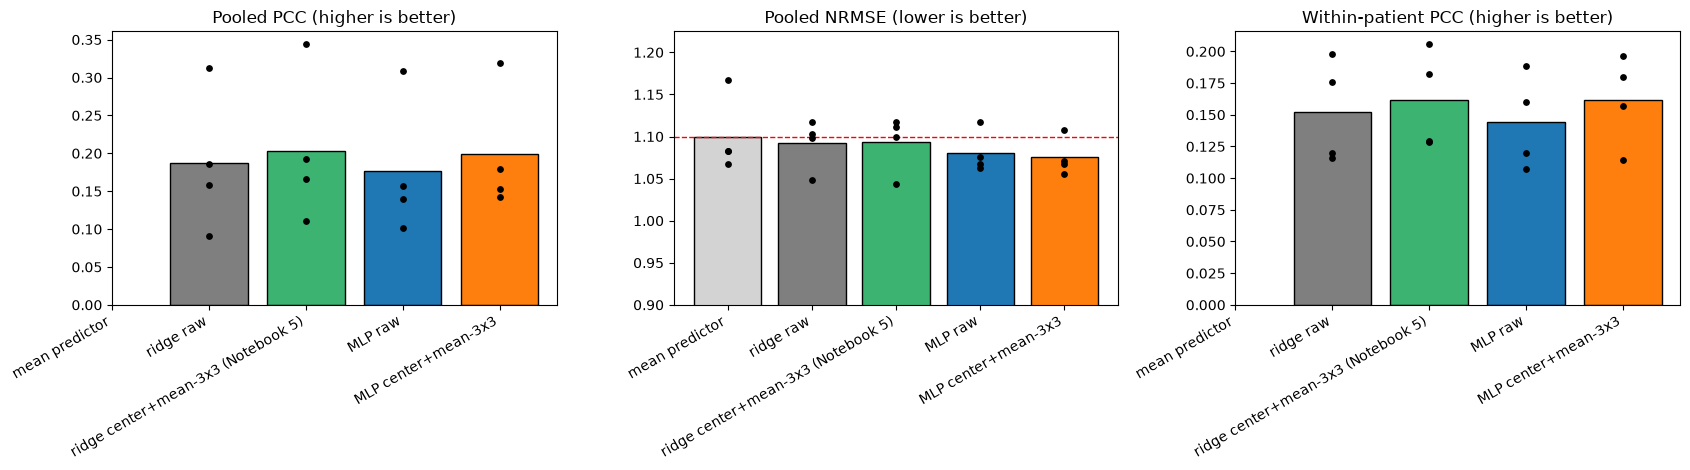

In [21]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    reference_name: "mediumseagreen",
    "MLP raw": "tab:blue",
    "MLP center+mean-3x3": "tab:orange",
}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
x = np.arange(len(model_order))
panels = [
    (axes[0], "PCC", "Pooled PCC (higher is better)"),
    (axes[1], "NRMSE", "Pooled NRMSE (lower is better)"),
    (axes[2], "PCC_within", "Within-patient PCC (higher is better)"),
]
for ax, column, title in panels:
    for i, model_name in enumerate(model_order):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=15, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=30, ha="right")
    ax.set_title(title)
axes[1].axhline(mean_predictor_nrmse, color="red", linestyle="--", linewidth=1)
axes[1].set_ylim(0.9, axes[1].get_ylim()[1])
plt.tight_layout()
save_figure("1_summary.png")
plt.show()

**Per fold.** Each line is one test fold. Lines going up or down together between two models means the difference is consistent across patients.

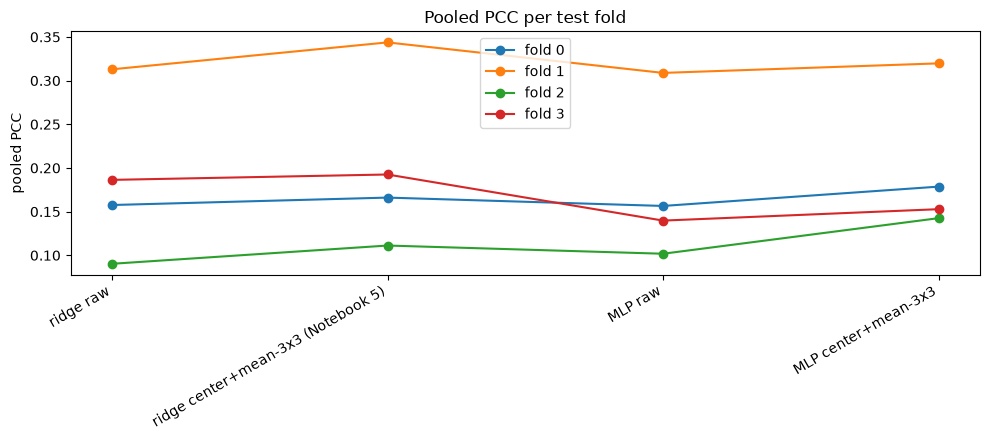

In [22]:
fold_table = fold_scores.pivot(index="model", columns="fold", values="PCC")
models_with_pcc = [m for m in model_order if m != "mean predictor"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for fold in range(N_FOLDS):
    values = [fold_table.loc[m, fold] for m in models_with_pcc]
    ax.plot(range(len(models_with_pcc)), values, marker="o", label=f"fold {fold}")
ax.set_xticks(range(len(models_with_pcc)))
ax.set_xticklabels(models_with_pcc, rotation=30, ha="right")
ax.set_ylabel("pooled PCC")
ax.set_title("Pooled PCC per test fold")
ax.legend()
plt.tight_layout()
save_figure("2_per_fold.png")
plt.show()

**Training and validation loss for the chosen setting.** Each panel is one test fold; the 4 thin lines of each color are the 4 validation groups. Loss is the MSE on standardized genes, so about 1.0 is what the mean predictor gets. Training loss falling while validation loss stays flat or rises means the model is learning things about the training patients that don't carry over to new patients.

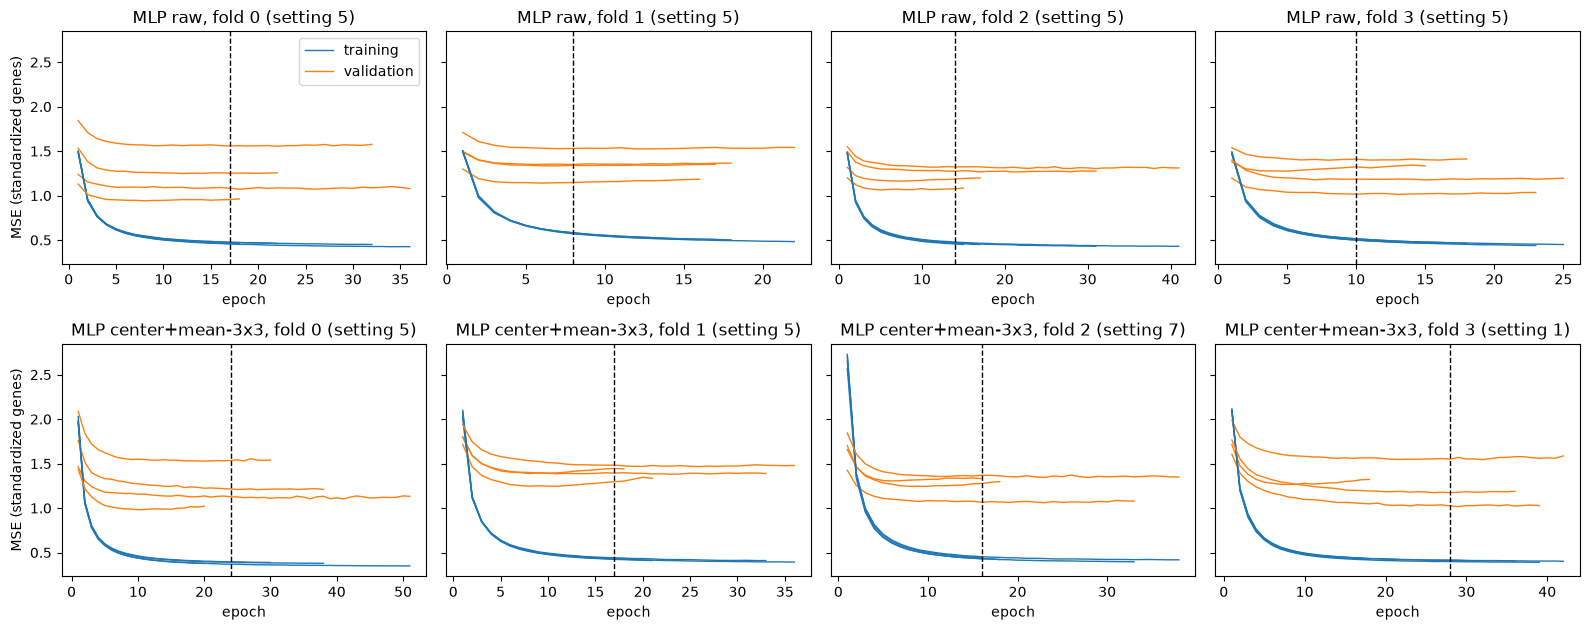

In [23]:
fig, axes = plt.subplots(len(MLP_CONDITIONS), N_FOLDS, figsize=(4 * N_FOLDS, 3.2 * len(MLP_CONDITIONS)),
                         squeeze=False, sharey=True)
for row, condition in enumerate(MLP_CONDITIONS):
    for fold in range(N_FOLDS):
        ax = axes[row, fold]
        chosen = chosen_settings[(chosen_settings["condition"] == condition) & (chosen_settings["fold"] == fold)].iloc[0]
        h = loss_history[(loss_history["condition"] == condition) & (loss_history["fold"] == fold)
                         & (loss_history["setting"] == chosen["setting"])]
        for group in range(N_VAL_GROUPS):
            g = h[h["val_group"] == group]
            ax.plot(g["epoch"], g["train_loss"], color="tab:blue", linewidth=1,
                    label="training" if group == 0 else None)
            ax.plot(g["epoch"], g["val_loss"], color="tab:orange", linewidth=1,
                    label="validation" if group == 0 else None)
        ax.axvline(chosen["final_epochs"], color="black", linestyle="--", linewidth=1)
        ax.set_title(f"MLP {condition}, fold {fold} (setting {int(chosen['setting'])})")
        ax.set_xlabel("epoch")
        if fold == 0:
            ax.set_ylabel("MSE (standardized genes)")
axes[0, 0].legend()
plt.tight_layout()
save_figure("3_loss_curves.png")
plt.show()

**Shrinkage.** Validation NRMSE of the chosen setting at each `k` (averaged over the 4 validation groups), one line per fold. The dashed lines are the mean predictor's validation NRMSE in each fold. Where the curve dips lowest is the `k` that fold chose. A minimum below 1.0 means the MLP's raw predictions were too spread out, and pulling them toward the mean helps.

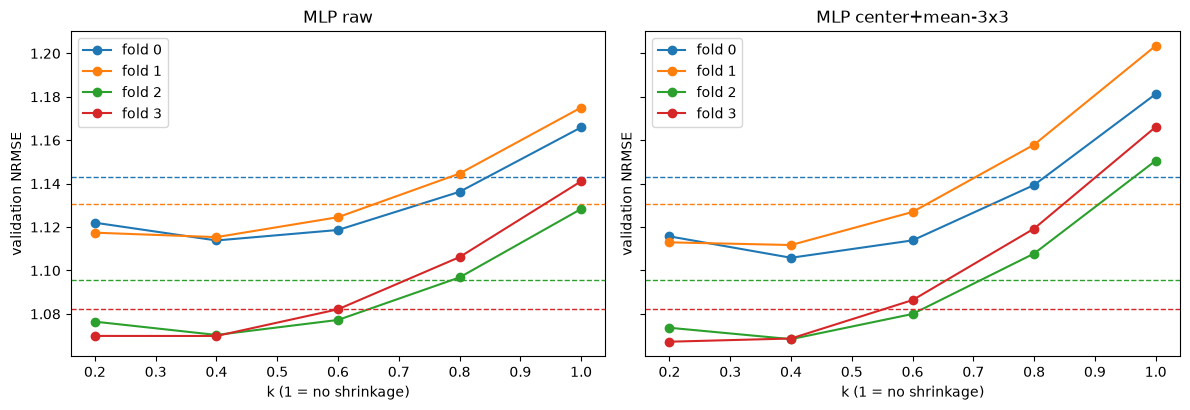

In [24]:
fig, axes = plt.subplots(1, len(MLP_CONDITIONS), figsize=(6 * len(MLP_CONDITIONS), 4.2), squeeze=False, sharey=True)
for col, condition in enumerate(MLP_CONDITIONS):
    ax = axes[0, col]
    for fold in range(N_FOLDS):
        chosen = chosen_settings[(chosen_settings["condition"] == condition) & (chosen_settings["fold"] == fold)].iloc[0]
        g = grid_scores[(grid_scores["condition"] == condition) & (grid_scores["fold"] == fold)
                        & (grid_scores["setting"] == chosen["setting"])]
        by_k = g.groupby("k")[["val_NRMSE", "val_mean_predictor_NRMSE"]].mean()
        line = ax.plot(by_k.index, by_k["val_NRMSE"], marker="o", label=f"fold {fold}")
        ax.axhline(by_k["val_mean_predictor_NRMSE"].iloc[0], color=line[0].get_color(), linestyle="--", linewidth=1)
    ax.set_xlabel("k (1 = no shrinkage)")
    ax.set_ylabel("validation NRMSE")
    ax.set_title(f"MLP {condition}")
    ax.legend()
plt.tight_layout()
save_figure("4_shrinkage.png")
plt.show()

## Step 15. Save results and add them to the log

`all_results.csv` gets one row per condition run in this notebook (the Notebook 5 reference row isn't added, since it wasn't run here). If this notebook is run again, its old rows are replaced instead of duplicated.

In [25]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
grid_scores.to_csv(os.path.join(OUT_DIR, "grid_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)
validation_summary.to_csv(os.path.join(OUT_DIR, "validation_summary.csv"), index=False)
loss_history.to_csv(os.path.join(OUT_DIR, "loss_history.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "mlp_conditions": MLP_CONDITIONS,
    "chosen_by_validation": chosen_condition,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "n_pcs": N_PCS,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_sizes": HIDDEN_SIZES,
    "dropouts": DROPOUTS,
    "weight_decays": WEIGHT_DECAYS,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        if row["model"] == reference_name:
            continue
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["pooled_NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row["val_PCC"],
            "val_NRMSE": row["val_NRMSE"],
            "date": today,
        })
    new_rows = pd.DataFrame(log_rows)
    if os.path.exists(RESULTS_LOG):
        old_rows = pd.read_csv(RESULTS_LOG)
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook           condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date
MLP_JK_01      mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-06
MLP_JK_01           ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-06
MLP_JK_01             MLP raw      0.1721              0.1434 1.1382                1.0997   0.1525     1.1353 2026-11-06
MLP_JK_01 MLP center+mean-3x3      0.2160              0.1563 1.1141                1.0997   0.1495     1.1303 2026-11-06
MLP_JK_02      mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-06
MLP_JK_02           ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-06
MLP_JK_02             MLP raw      0.1767              0.1433 1.0806                1.0997   0.1898     1.0923 2026-11-06
MLP_JK_02 MLP center+mea

## Summary in plain words

**Check first:** ridge on raw embeddings gave pooled PCC 0.1868 and NRMSE 1.0917, the same as Notebook 5. The numbers below can be compared with Notebook 5 and MLP_JK_01.

### What each score means, and what we got

| Score | What it means | Good vs. bad | Mean predictor | Ridge raw | Best ridge (NB 5) | MLP raw | MLP center+mean-3x3 |
|---|---|---|---|---|---|---|---|
| **Pooled PCC** (test) | Correlation between predicted and true expression over all test spots, averaged over the 50 genes. Does the model put high-expression spots high and low ones low? | 0 = no relation, 1 = perfect. ~0.2 is the level to beat here | — | 0.187 | **0.203** | 0.177 | 0.198 |
| **Within-patient PCC** (test) | The same correlation, inside one test patient at a time. Does the model rank spots correctly *within* a tissue? | Higher is better | — | 0.151 | **0.161** | 0.143 | **0.161** |
| **Pooled NRMSE** (test) | Size of the prediction error divided by how much the gene varies. Punishes predictions at the wrong level or with too much spread | Lower is better. Below the mean predictor = closer to the truth than guessing the average | 1.100 | 1.092 | 1.093 | 1.081 | **1.075** |
| **Validation PCC** | Pooled PCC on held-out *training* patients, averaged over 4 validation groups. Used to choose | Higher is better | — | — | — | 0.190 | **0.211** |
| **Validation NRMSE** | NRMSE on the same validation patients. Must be no worse than the mean predictor there (1.113) | Lower is better | 1.113 | — | — | 1.092 | **1.088** |

### What it means

1. **Shrinkage fixed the NRMSE problem.** Both MLPs now beat the mean predictor, on validation and on test. `MLP center+mean-3x3` has the **lowest NRMSE of any model so far** (1.075, vs. 1.092 for ridge). In 7 of 8 fold × input combinations, the chosen `k` was 0.4. The plain MLP's predictions were about 2.5 times too spread out, and pulling them 60% of the way back toward the mean made them more accurate (see the shrinkage plot: every curve is lowest at `k` = 0.2–0.4 and highest at `k` = 1).
2. **PCC is about the same as the best ridge, not better.** `MLP center+mean-3x3` has pooled PCC 0.198 vs. 0.203 for the best ridge (higher in folds 0 and 2, lower in 1 and 3), and the same within-patient PCC (0.161). It's lower than MLP_JK_01's 0.216. Shrinking can't change PCC, so that drop comes from the other changes: the PCA input and the smaller hidden layer.
3. **The settings matter little.** All 8 settings score between 0.173 and 0.210 on validation PCC. A hidden size of 128 beat 64 every time, weight decay 1e-3 was slightly better than 1e-4, and dropout made almost no difference. Setting 5 (128 hidden, dropout 0.3, weight decay 1e-3) was chosen in 6 of 8 cases. 128 was the largest size in the grid, so a larger hidden layer might help.
4. **Validation is now more trustworthy.** Averaging over 4 validation groups gave the same ranking as the test set (center+mean-3x3 above raw), unlike in 01.
5. **The network still overfits.** Training loss falls to ~0.4 while validation loss levels off at ~1.0–1.5. With PCA input and weight decay, validation loss no longer gets worse with more epochs; it just stops improving.

### Decision
`MLP center+mean-3x3` passes the rule (highest validation PCC, 0.211; validation NRMSE 1.088 ≤ mean predictor 1.113), so it becomes **MLP_JK_Best**. It's the first MLP to qualify.

**Possible next steps:** add shrinkage to MLP_JK_01's full 9,216-number input (which had higher PCC), or try a larger hidden layer (256) with PCA input.